# Training Basics: Fitting Functions with a Neural Network

**Author:** Nassim Razaaly ([nassim.razaaly@ensma.fr](mailto:nassim.razaaly@ensma.fr))<br>
**First version:** October 15, 2026<br>
**Last updated:** October 19, 2026

Follow-up of the *PyTorch Tutorial* notebook. Two problems, solved with an MLP:

1. **A 1D function** $f(x)$ learned from noisy measurements.
2. **An image**, seen as a function $(x, y) \mapsto$ gray level (or color).

You will learn to choose the **hyperparameters**: learning rate, number of epochs, mini-batches, architecture (layers, neurons, activation functions). To go further: learning rate schedules and **Fourier features**.

> **Colab:** *File → Save a copy in Drive* first. Runs on CPU; a GPU (*Runtime → Change runtime type*) is faster.

In [1]:
# Outside Colab only:
# !pip install "torch>=2.0" numpy matplotlib tqdm

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cbook                  # matplotlib's sample images
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm                    # progress bars

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

torch 2.11.0+cpu | device: cpu


## 0. The model: a general MLP

`layers` gives the size of each layer: `[1, 64, 64, 1]` = 1 input, 2 hidden layers of 64 neurons, 1 output.

* **`activation`** (hidden layers): `nn.ReLU` (default choice, fast), `nn.Tanh` (smooth, good for smooth functions), `nn.SiLU` / `nn.GELU` (smooth versions of ReLU).
* **`last_activation`** (output): `None` for regression (any real value), `nn.Sigmoid` for an output in $[0, 1]$ (e.g. pixels), `nn.Softmax` for probabilities (classification).

In [2]:
class MLP(nn.Module):
    def __init__(self, layers, activation, last_activation=None):
        super().__init__()
        blocks = []
        for n_in, n_out in zip(layers[:-2], layers[1:-1]):      # hidden layers
            blocks += [nn.Linear(n_in, n_out), activation()]
        blocks.append(nn.Linear(layers[-2], layers[-1]))        # output layer
        if last_activation is not None:
            blocks.append(last_activation())
        self.net = nn.Sequential(*blocks)

    def forward(self, x):
        return self.net(x)

    def n_params(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def __repr__(self):
        return f"{super().__repr__()}\nTotal params: {self.n_params():,}"

example = MLP([1, 64, 64, 1], nn.Tanh)
print(example)


MLP(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Total params: 4,353


## 1. A 1D function

The true function is

$$f(x) = \sin(3x) + 0.3\,x^2 - 1.5\,e^{-10(x-1)^2}$$

In practice $f$ is unknown: we only have noisy measurements $y = f(x) + \varepsilon$. Here we choose it, so we can check what the model learns.

In [3]:
def f(x):
    return torch.sin(3 * x) + 0.3 * x**2 - 1.5 * torch.exp(-10 * (x - 1) ** 2)

### 1.1 Data: split and normalization

The $N$ points are split **at random** into three sets:

* **training** (60 %): to update the weights;
* **validation** (20 %): to monitor training and choose the hyperparameters;
* **test** (20 %): used **once**, at the end, to measure the error on unseen points.

**Normalization:** networks train best when inputs and outputs are of order 1. We use $\tilde x = (x - \bar x)/\sigma_x$ (same for $y$), with the mean and standard deviation of the **training** set only. Predictions are transformed back with $y = \bar y + \sigma_y\,\tilde y$.

In [4]:
def generate_data(N, noise, train=0.6, val=0.2, test=0.2, seed=0):
    assert abs(train + val + test - 1) < 1e-9
    g = torch.Generator().manual_seed(seed)
    x = torch.rand(N, 1, generator=g) * 6 - 3                  # uniform in [-3, 3]
    y = f(x) + noise * torch.randn(N, 1, generator=g)          # noisy measurements

    perm = torch.randperm(N, generator=g)
    n_tr, n_va = int(train * N), int(val * N)
    idx = {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}

    # plot
    x_grid = torch.linspace(-3, 3, 500)[:, None]
    plt.figure(figsize=(8, 3.5))
    plt.plot(x_grid, f(x_grid), "k", label="true function")
    for name, i in idx.items():
        plt.scatter(x[i], y[i], s=10, label=f"{name} ({len(i)})")
    plt.legend(); plt.title(f"Data: N = {N}, noise = {noise}"); plt.show()

    # normalization with the statistics of the training set
    tr = idx["train"]
    norm = {"x": (x[tr].mean(), x[tr].std()), "y": (y[tr].mean(), y[tr].std())}
    data = {}
    for name, i in idx.items():
        xn = (x[i] - norm["x"][0]) / norm["x"][1]
        yn = (y[i] - norm["y"][0]) / norm["y"][1]
        data[name] = (xn.to(device), yn.to(device))
    return data, norm

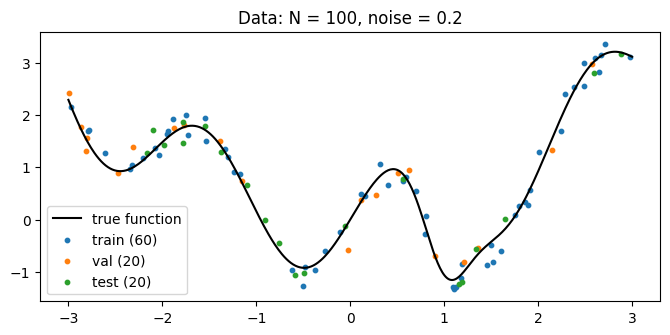

In [7]:
# Function to animate batch data
import math, numpy as np, torch, matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from matplotlib.colors import to_rgba
from IPython.display import HTML

def animate_minibatches(data, n_batch=4, n_epochs=3, seed=0, interval=800):
    np_ = lambda t: t.detach().cpu().squeeze().numpy()
    x, y = map(np_, data["train"])
    xo = np.concatenate([np_(data[k][0]) for k in ("val", "test")])
    yo = np.concatenate([np_(data[k][1]) for k in ("val", "test")])
    N = len(x); bs = math.ceil(N / n_batch); nb = math.ceil(N / bs)
    g = torch.Generator().manual_seed(seed)
    batch_of = []                                   # batch_of[e][i] = n° du batch du point i à l'epoch e
    for e in range(n_epochs):
        b = np.empty(N, int); b[torch.randperm(N, generator=g).numpy()] = np.arange(N) // bs
        batch_of.append(b)

    C = "C0"; cC, cL, cG = to_rgba(C), to_rgba(C, .3), to_rgba("lightgray")
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
    ax.scatter(xo, yo, s=8, c="lightgray", label="val/test")
    ax.scatter(x, y, s=12, c=C, alpha=.12, label=f"train ({N})")
    seen = ax.scatter([], [], s=14, c=C, alpha=.4, label="Already seen")
    cur = ax.scatter([], [], s=50, c=C, edgecolors="k", label="current")
    ax.legend(loc="upper left", fontsize=8)
    rast = ax2.scatter(x, np.zeros(N), s=80, marker="|")
    hl = ax2.add_patch(Rectangle((0, -.5), 1, 1, transform=ax2.get_yaxis_transform(), color=C, alpha=.15))
    ax2.set(ylim=(nb - .5, -.5), yticks=range(nb), yticklabels=range(1, nb + 1), ylabel="batch n°", xlabel="x")

    def update(f):
        e, k = f; b = batch_of[e]
        seen.set_offsets(np.c_[x[b < k], y[b < k]])
        cur.set_offsets(np.c_[x[b == k], y[b == k]])
        rast.set_offsets(np.c_[x, b])
        rast.set_color(np.where((b == k)[:, None], cC, np.where((b < k)[:, None], cL, cG)))
        hl.set_y(k - .5)
        ax.set_title(f"Epoch {e+1}/{n_epochs} · batch {k+1}/{nb} (≤{bs} pts)" + ("  →  new shuffle !" if k == 0 else ""),
                     color="crimson" if k == 0 else "k")
        return seen, cur, rast, hl

    plt.close(fig)
    return FuncAnimation(fig, update, frames=[(e, k) for e in range(n_epochs) for k in range(nb)], interval=interval)

# --- lancement ---
data, norm = generate_data(N=100, noise=0.2)   # ou ton `data` existant
anim = animate_minibatches(data, n_batch=4, n_epochs=3)
HTML(anim.to_jshtml())


### 1.2 Model and optimizer initialization

All the choices of the training are made in the cell below; you will change them a lot:

* **`N`, `noise`**: number of measurements and standard deviation of their noise.
* **Architecture** `MLP([1, 32, 1], ...)`: 1 input ($x$), the sizes of the hidden layers (here one layer of 32 neurons), 1 output ($y$). More layers or neurons give a more expressive model, but slower to train and more prone to overfitting.
* **`activation`**: the nonlinear function applied after each hidden layer (section 0).
* **Optimizer** `Adam`: gradient descent where each parameter has its own step size, adapted along the training. The default choice.
* **Learning rate** `lr`: the step size of the optimizer. Too small: the loss decreases slowly; too large: the loss is noisy or diverges.
* **`n_epochs`**: number of epochs; one epoch is one pass over the whole training set.
* **`n_batch`**: number of mini-batches per epoch. The weights are updated `n_batch` times per epoch, each time with $N_{train}/$`n_batch` points. `n_batch = 1` is the full batch: one update per epoch.

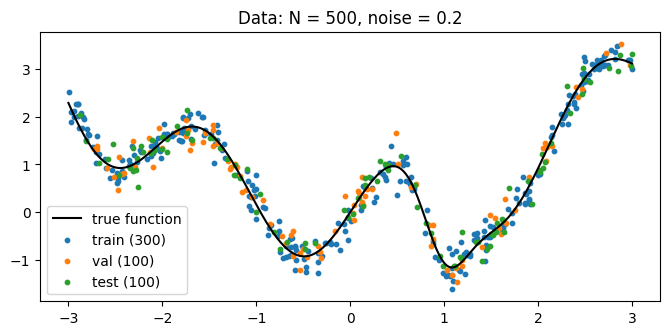

In [5]:
torch.manual_seed(0)
data, norm = generate_data(N=500, noise=0.2)

model = MLP([1, 32, 1], activation=nn.Tanh).to(device)      # 1 input, 1 hidden layer of 32 neurons, 1 output
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
n_epochs = 2000
n_batch = 2                                                   # 2 updates per epoch, of N_train / 2 points each

### 1.3 Training

We now train the model with the loop below. At each epoch:

1. **training:** the training points are shuffled (`torch.randperm`) and cut into `n_batch` mini-batches (`.chunk`); for each one, the loss is computed, its gradient back-propagated, and the weights updated;
2. **monitoring:** the MSE on the whole training and validation sets is computed without gradients (`torch.no_grad()`) and stored in `hist`;
3. **live plot:** every 100 epochs, the loss curves are redrawn.

Later (section 1.5), this loop is put in a function, to run many trainings easily.

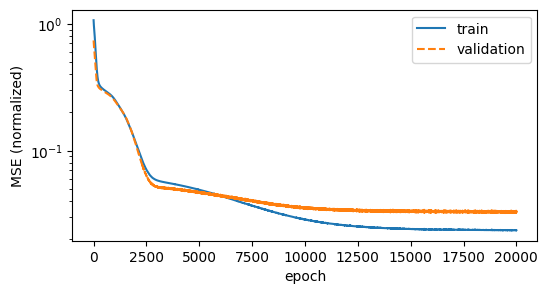

  0%|          | 0/20000 [00:00<?, ?it/s]

In [ ]:
loss_fn = nn.MSELoss()
X, Y = data["train"]
X_val, Y_val = data["val"]
hist = {"train": [], "val": []}
fig, ax = plt.subplots(figsize=(6, 3)); live = display(fig, display_id=True); plt.close(fig)

for epoch in tqdm(range(n_epochs)):
    # 1. training, by mini-batches
    model.train()
    for idx in torch.randperm(len(X), device=X.device).chunk(n_batch):
        optimizer.zero_grad()
        loss = loss_fn(model(X[idx]), Y[idx])
        loss.backward()
        optimizer.step()

    # 2. monitoring
    model.eval()
    with torch.no_grad():
        hist["train"].append(loss_fn(model(X), Y).item())
        hist["val"].append(loss_fn(model(X_val), Y_val).item())

    # 3. live plot
    if (epoch + 1) % 100 == 0:
        ax.clear()
        ax.semilogy(hist["train"], label="train"); ax.semilogy(hist["val"], "--", label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel("MSE (normalized)"); ax.legend()
        live.update(fig)

### 1.4 Check model

We now look at how the trained model behaves:

* the **MSE on the training, validation and test sets**, in the original units of $y$ ($\text{MSE} = \sigma_y^2 \times$ normalized MSE). They are the quantitative measure of the training: the validation MSE is used to compare settings, the test MSE gives the final error on unseen points;
* the **prediction** of the MLP, transformed back to the original units, compared with the true function and the data.

train MSE = 0.0400
val   MSE = 0.0562
test  MSE = 0.0488


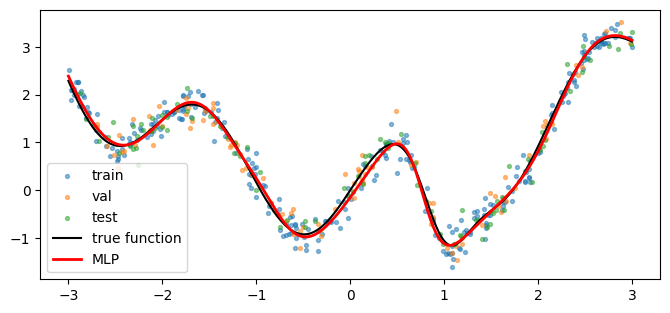

In [ ]:
def predict(model, x, norm):                     # x in original units -> prediction in original units
    model.eval()
    with torch.no_grad():
        y = model(((x - norm["x"][0]) / norm["x"][1]).to(device)).cpu()
    return norm["y"][0] + norm["y"][1] * y

for name, (X, Y) in data.items():
    with torch.no_grad():
        mse = loss_fn(model(X), Y).item() * norm["y"][1].item() ** 2
    print(f"{name:5s} MSE = {mse:.4f}")

x_grid = torch.linspace(-3, 3, 500)[:, None]
plt.figure(figsize=(8, 3.5))
for name, (X, Y) in data.items():                # data back in original units
    plt.scatter(norm["x"][0] + norm["x"][1] * X.cpu(), norm["y"][0] + norm["y"][1] * Y.cpu(), s=8, alpha=0.5, label=name)
plt.plot(x_grid, f(x_grid), "k", label="true function")
plt.plot(x_grid, predict(model, x_grid, norm), "r", lw=2, label="MLP")
plt.legend(); plt.show()

### 1.5 Exercises

1. **Improve the prediction.** Change `N`, the architecture (number of hidden layers and of neurons), the activation, `lr`, `n_epochs` and `n_batch` to get the lowest validation MSE you can. Compute the test MSE only once, for your final model.
2. **Effect of the noise.** Redo exercise 1 with a very small noise (`noise = 0.01`), then with the original noise (`noise = 0.2`). Compare the best MSE reached and the predicted curves in the two cases.
3. **Overfitting.** Use a large model, few points and many epochs, until the validation loss starts to increase while the training loss keeps decreasing. Look at the predicted curve, then propose and test a way to avoid it.
4. **Activation function.** Compare `nn.ReLU`, `nn.Tanh` and `nn.SiLU` with the same other settings, and explain which one works best for this function.

**To go further:**

* **Learning rate schedule:** a large learning rate at the beginning (fast progress), a small one at the end (precise minimum). Create a scheduler after the optimizer, and give it to the `train` function below (`scheduler=scheduler`):
  ```python
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)      # cosine from lr to 0
  scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)       # halved every 500 epochs
  scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.999)             # x 0.999 per epoch
  ```
* Create your own function in 1D, 2D or $n$D, generate noisy data from it, and train an MLP on it.

**To help you:** the training loop of section 1.3 as a function. `hist = train(model, optimizer, data, n_epochs, n_batch)` does the same training as above. Optional arguments:

* `plot_every`: the loss curves are redrawn every `plot_every` epochs;
* `scheduler`: a learning rate scheduler, updated once per epoch (`scheduler.step()`);
* `snapshot`: a function **without argument**, called every `plot_every` epochs; what it returns is stored in the list `hist["snapshots"]`. Use it to keep the state of the model along the training, e.g. `snapshot=lambda: predict(model, x_grid, norm)` stores the predicted curve, to plot or animate its evolution.

In [ ]:
def train(model, optimizer, data, n_epochs, n_batch, plot_every=100, scheduler=None, snapshot=None):
    X, Y = data["train"]
    X_val, Y_val = data["val"]
    hist = {"train": [], "val": [], "snapshots": []}
    fig, ax = plt.subplots(figsize=(6, 3)); live = display(fig, display_id=True); plt.close(fig)

    for epoch in tqdm(range(n_epochs)):
        model.train()
        for idx in torch.randperm(len(X), device=X.device).chunk(n_batch):
            optimizer.zero_grad()
            loss = loss_fn(model(X[idx]), Y[idx])
            loss.backward()
            optimizer.step()
        if scheduler is not None:
            scheduler.step()

        model.eval()
        with torch.no_grad():
            hist["train"].append(loss_fn(model(X), Y).item())
            hist["val"].append(loss_fn(model(X_val), Y_val).item())

        if (epoch + 1) % plot_every == 0 or epoch == n_epochs - 1:
            if snapshot is not None:
                hist["snapshots"].append(snapshot())
            ax.clear()
            ax.semilogy(hist["train"], label="train"); ax.semilogy(hist["val"], "--", label="validation")
            ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend()
            live.update(fig)
    return hist

## 2. An image

### 2.1 An image is a function

A black-and-white image of $n \times n$ pixels is an array of gray levels, often stored as integers in $[0, 255]$; we divide by 255 to get values in $[0, 1]$ (0 = black, 1 = white). A color image has 3 channels $(r, g, b)$: an $n \times n \times 3$ array.

We see it as a function $f : [-1, 1]^2 \to [0, 1]$, $(x, y) \mapsto$ gray level, known only at the pixels, and approximate it by an MLP $f_{\boldsymbol\omega}$ by minimizing the MSE over the training pixels.

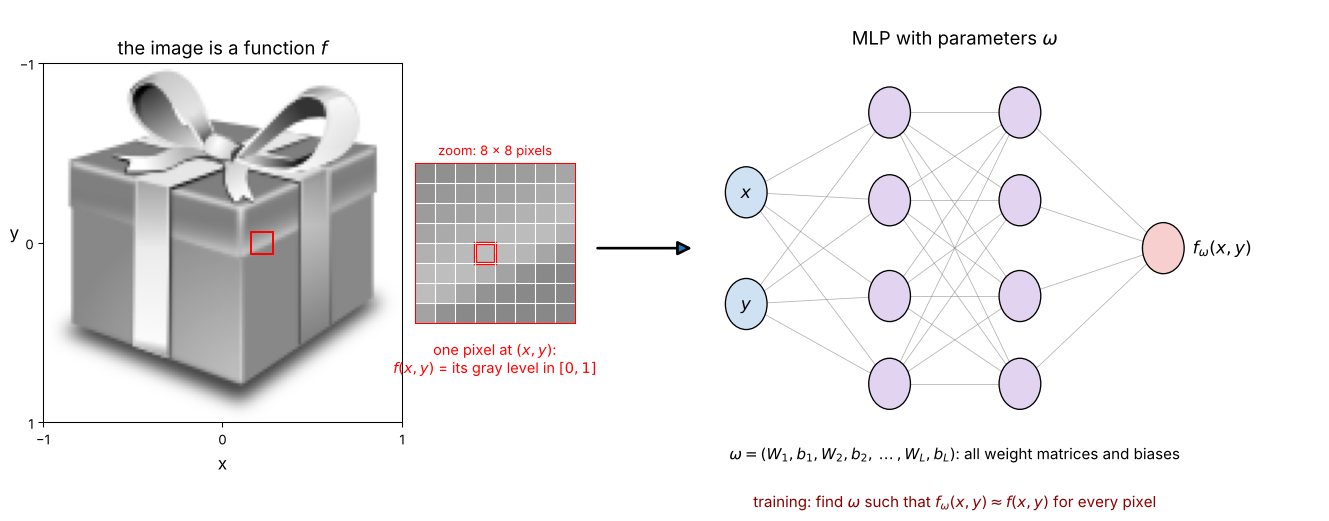

`load_image` reads a file, puts it in $[0, 1]$, crops the central square and resizes it to `size` $\times$ `size` pixels.

shape: (128, 128) | values in (0.0, 1.0)


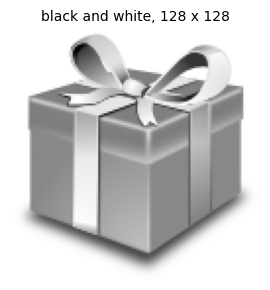

In [ ]:
def load_image(path, size=128, gray=False):
    raw = plt.imread(path)
    im = torch.tensor(raw, dtype=torch.float32)
    if raw.dtype == np.uint8:
        im = im / 255                                         # [0, 255] -> [0, 1]
    if im.ndim == 2:
        im = im[..., None]                                    # (H, W) -> (H, W, 1)
    if im.shape[2] == 4:                                      # transparency -> white background
        im = im[..., :3] * im[..., 3:] + 1 - im[..., 3:]
    H, W = im.shape[:2]; s = min(H, W)                        # central square
    im = im[(H - s) // 2:(H - s) // 2 + s, (W - s) // 2:(W - s) // 2 + s]
    im = F.interpolate(im.permute(2, 0, 1)[None], size=(size, size), mode="area")[0].permute(1, 2, 0)
    if gray:
        im = im.mean(dim=2, keepdim=True)
    return im.squeeze(2)                                      # (n, n) if gray, (n, n, 3) if color

def show_images(images, titles, size=3):
    fig, ax = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for a, im, t in zip(np.atleast_1d(ax), images, titles):
        a.imshow(np.clip(im, 0, 1), cmap="gray", vmin=0, vmax=1); a.set_title(t, fontsize=10); a.axis("off")
    plt.tight_layout(); plt.show()

img = load_image(cbook.get_sample_data("Minduka_Present_Blue_Pack.png", asfileobj=False), gray=True)
print("shape:", tuple(img.shape), "| values in", (img.min().item(), img.max().item()))
show_images([img.numpy()], ["black and white, 128 x 128"])

### 2.2 Data

One sample per pixel: **input** its position $(x, y) \in [-1, 1]^2$ (already normalized), **output** its intensity in $[0, 1]$ (1 value in gray, 3 in color). Pixels are split at random, 60 / 20 / 20 %: the model never sees the validation and test pixels and must fill them in.

In [ ]:
def image_data(img, train=0.6, val=0.2, seed=0):
    n = img.shape[0]
    t = torch.linspace(-1, 1, n)
    yy, xx = torch.meshgrid(t, t, indexing="ij")             # y: rows, x: columns
    X = torch.stack([xx.flatten(), yy.flatten()], dim=1)      # (n*n, 2)
    Y = img.reshape(n * n, -1)                                # (n*n, 1) or (n*n, 3)
    perm = torch.randperm(n * n, generator=torch.Generator().manual_seed(seed))
    n_tr, n_va = int(train * n * n), int(val * n * n)
    idx = {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}
    data = {k: (X[i].to(device), Y[i].to(device)) for k, i in idx.items()}
    return data, X.to(device)                                 # X_all: all pixels, to draw the image

def predict_image(model, X_all, shape):
    model.eval()
    with torch.no_grad():
        return model(X_all).cpu().numpy().reshape(shape)

def psnr(mse):                                                # peak signal-to-noise ratio, in dB (peak = 1)
    return 10 * np.log10(1 / mse)

data_img, X_all = image_data(img)
print({k: len(v[0]) for k, v in data_img.items()})

{'train': 9830, 'val': 3276, 'test': 3278}


**Image quality: PSNR** $= 10 \log_{10}(1 / \text{MSE})$, in dB, higher is better. Around 20 dB the image is blurry but recognizable; above 30 dB, differences are hard to see.

### 2.3 Model and optimizer initialization

Same choices as in section 1.2, with two differences:

* **architecture:** 2 inputs $(x, y)$ and 1 output (gray level); an image has many more details than the 1D function, so the network is larger;
* **`last_activation = nn.Sigmoid`**: keeps the output in $[0, 1]$, like the pixels. The untrained model gives a uniform gray image.

With about 10 000 training pixels, `n_batch = 100` gives mini-batches of about 100 pixels, so 100 updates per epoch.

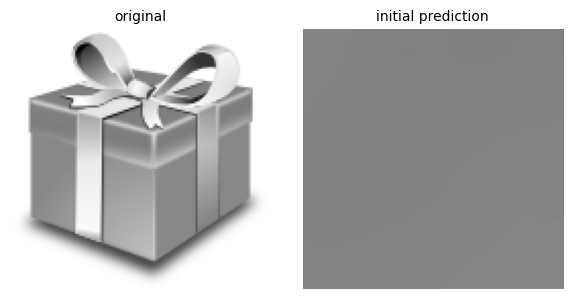

In [ ]:
torch.manual_seed(0)
model = MLP([2, 64, 1], activation=nn.ReLU, last_activation=nn.Sigmoid).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
n_epochs = 30
n_batch = 100

initial = predict_image(model, X_all, img.shape)
show_images([img.numpy(), initial], ["original", "initial prediction"])

### 2.4 Training

Train the model with the `train` function of section 1.5. To see the image evolve during the training, store one predicted image per epoch with `plot_every=1` and `snapshot=lambda: predict_image(model, X_all, img.shape)`.

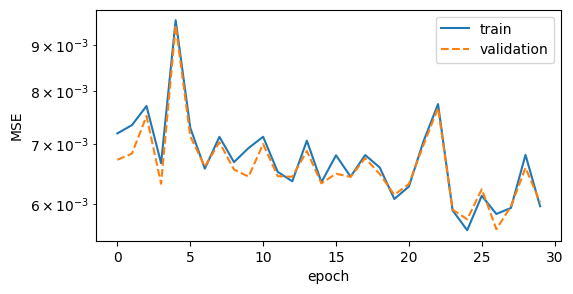

  0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
hist=train(model, optimizer, data_img, n_epochs, n_batch, plot_every=1, scheduler=None, snapshot=lambda: predict_image(model, X_all, img.shape))

### 2.5 Check model

As in section 1.4: the MSE and the PSNR on the three sets, and the predicted image (on **all** the pixels, including the validation and test ones, never seen during the training).

train MSE = 0.00596 | PSNR = 22.2 dB
val   MSE = 0.00602 | PSNR = 22.2 dB
test  MSE = 0.00641 | PSNR = 21.9 dB


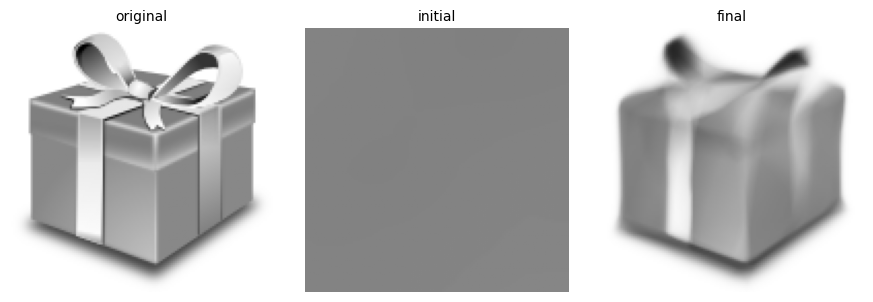

In [ ]:
for name, (X, Y) in data_img.items():
    with torch.no_grad():
        mse = loss_fn(model(X), Y).item()
    print(f"{name:5s} MSE = {mse:.5f} | PSNR = {psnr(mse):.1f} dB")
show_images([img.numpy(), initial, predict_image(model, X_all, img.shape)], ["original", "initial", "final"])

**Animation** of the predicted image along the training (uses `hist["snapshots"]`):

In [ ]:
frames = hist["snapshots"]
fig, ax = plt.subplots(figsize=(3.5, 3.5)); ax.axis("off")
im_plot = ax.imshow(np.clip(frames[0], 0, 1), cmap="gray", vmin=0, vmax=1)
def update(k):
    im_plot.set_data(np.clip(frames[k], 0, 1)); ax.set_title(f"snapshot {k + 1}/{len(frames)}")
anim = FuncAnimation(fig, update, frames=len(frames), interval=150)
plt.close(fig); HTML(anim.to_jshtml())

### 2.6 Exercises

1. **Improve the prediction.** Change the architecture, the activation, `lr`, `n_epochs`, `n_batch` and the learning rate schedule to get the highest validation PSNR you can, and note the training time of each setting.
2. **What is learned first?** Look at the animation: which parts of the image (smooth areas, edges) appear first, and which ones stay blurry?
3. **Color.** Fit the color image below: the output has 3 values $(r, g, b)$, so only the size of the last layer changes.
4. **Your own image.** Upload it (Colab: folder icon on the left), load it with `load_image("my_image.jpg", size=...)`, and train on it. Try a bigger size.

In [ ]:
img_color = load_image(cbook.get_sample_data("grace_hopper.jpg", asfileobj=False), size=128)
# img_color = load_image("my_image.jpg", size=128)          # your own image
data_color, X_all = image_data(img_color)
show_images([img_color.numpy()], ["color, 128 x 128"])

### 2.7 Going further: Fourier features

An MLP with inputs $(x, y)$ learns low frequencies easily, high frequencies (details, edges) very slowly. **Fourier features** (Tancik et al., 2020) give them directly: the input $v = (x, y)$ is first mapped to

$$\gamma(v) = \left[\cos(2\pi B v),\ \sin(2\pi B v)\right] \in \mathbb{R}^{2m}$$

where $B$ is an $m \times 2$ matrix with entries drawn from $\mathcal N(0, \sigma^2)$: $m$ frequencies (`n_freq`), so $2m$ features (cos and sin). $\sigma$ sets their size: small $\sigma$, smooth fit; large $\sigma$, fine details... and noise between the training pixels (overfitting).

$B$ is an `nn.Parameter`: fixed (`trainable=False`, `requires_grad=False`) or learned with the other weights (`trainable=True`).

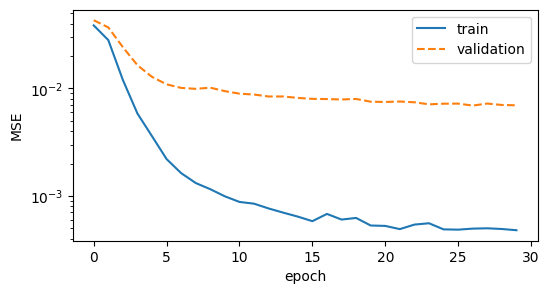

  0%|          | 0/30 [00:00<?, ?it/s]

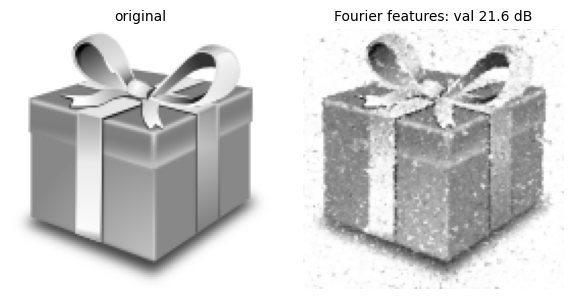

In [ ]:
class FourierFeatures(nn.Module):
    def __init__(self, n_in, n_freq, sigma, trainable=False):
        super().__init__()
        self.B = nn.Parameter(sigma * torch.randn(n_freq, n_in), requires_grad=trainable)

    def forward(self, v):                                     # (N, n_in) -> (N, 2 * n_freq)
        z = 2 * torch.pi * v @ self.B.T
        return torch.cat([torch.cos(z), torch.sin(z)], dim=1)

torch.manual_seed(0)
n_freq, sigma = 128, 10
data_img, X_all = image_data(img)
model = nn.Sequential(FourierFeatures(2, n_freq, sigma),
                      MLP([2 * n_freq, 128, 128, 1], activation=nn.ReLU, last_activation=nn.Sigmoid)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
hist_ff = train(model, optimizer, data_img, n_epochs=30, n_batch=100, plot_every=5)

show_images([img.numpy(), predict_image(model, X_all, img.shape)],
            ["original", f"Fourier features: val {psnr(hist_ff['val'][-1]):.1f} dB"])

**Exercises.**

1. Compare with the MLP without Fourier features, trained for the same number of epochs: sharpness of the image and validation PSNR.
2. Try $\sigma = 1, 3, 10, 30$ and `n_freq = 16, 64, 256`. Choose the best setting **on the validation set**, then compute its test PSNR once.
3. With a large $\sigma$, plot the training and validation curves and find where the overfitting appears.
4. Make $B$ trainable (`trainable=True`) and compare with a fixed $B$.
5. Apply Fourier features to the color image and to your own image.